
# 1-EDA: Exploratory Data Analysism

In [2]:
import pandas as pd
train_url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/train.csv"
test_url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/test.csv"

df_train = pd.read_csv(train_url)
df_test = pd.read_csv(test_url)

df_train.head(10)

,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival
5,When did you send me my new card?,card_arrival
6,Do you have info about the card on delivery?,card_arrival
7,What do I do if I still have not received my n...,card_arrival
8,Does the package with my card have tracking?,card_arrival
9,I ordered my card but it still isn't here,card_arrival


In [20]:
df_train['category'].unique().sum()


AttributeError: 'ArrowStringArray' object has no attribute 'sum'

In [4]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   text      10003 non-null  str  
 1   category  10003 non-null  str  
dtypes: str(2)
memory usage: 943.8 KB


In [5]:
{
    "train_missing": df_train.isnull().sum().to_dict(),
    "test_missing": df_test.isnull().sum().to_dict(),
    "train_duplicates": int(df_train.duplicated(subset=['text']).sum())
}

{'train_missing': {'text': 0, 'category': 0},
 'test_missing': {'text': 0, 'category': 0},
 'train_duplicates': 0}

In [6]:
class_counts = df_train['category'].value_counts()

pd.DataFrame({
    "Metric": ["Total Classes", "Max per Class", "Min per Class", "Mean per Class"],
    "Value": [len(class_counts), class_counts.max(), class_counts.min(), round(class_counts.mean(), 1)]
})

,Metric,Value
0,Total Classes,77.0
1,Max per Class,187.0
2,Min per Class,35.0
3,Mean per Class,129.9


In [7]:
df_train['word_count'] = df_train['text'].apply(lambda x: len(x.split()))
df_train['char_count'] = df_train['text'].apply(len)

df_train[['word_count', 'char_count']].describe().round(1)

,word_count,char_count
count,10003.0,10003.0
mean,11.9,59.5
std,7.9,40.9
min,2.0,13.0
25%,7.0,36.0
50%,10.0,47.0
75%,13.0,64.0
max,79.0,433.0


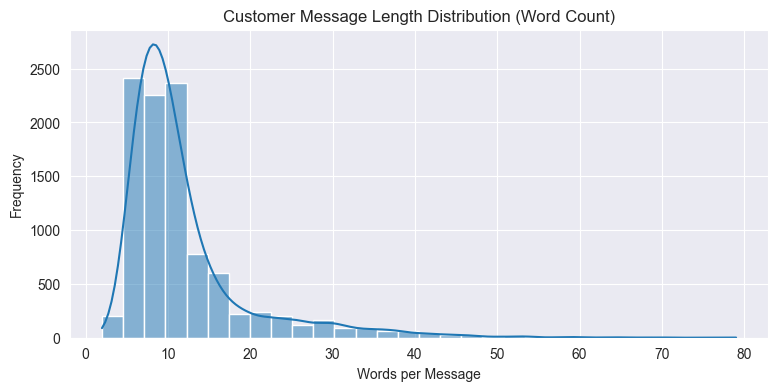

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 4))
sns.histplot(df_train['word_count'], bins=30, kde=True, color='#1f77b4')
plt.title("Customer Message Length Distribution (Word Count)", fontsize=12)
plt.xlabel("Words per Message")
plt.ylabel("Frequency")

plt.savefig("word_length_distribution.png", dpi=200, bbox_inches='tight')
plt.show()

In [9]:
from collections import Counter

all_words = " ".join(df_train['text']).lower().split()
top_words = Counter(all_words).most_common(15)

pd.DataFrame(top_words, columns=['Word', 'Frequency'])

,Word,Frequency
0,i,8309
1,my,5684
2,to,4011
3,a,3565
4,the,3497
5,is,2339
6,can,1839
7,do,1730
8,card,1636
9,it,1557


In [10]:
pd.concat([
    df_train[df_train['category'] == 'card_arrival'][['text', 'category']].head(3),
    df_train[df_train['category'] == 'card_delivery_estimate'][['text', 'category']].head(3)
]).reset_index(drop=True)

,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can it specifically be delivered on a certain ...,card_delivery_estimate
4,I need to get my card quickly,card_delivery_estimate
5,When can I expect my card? I live in the US.,card_delivery_estimate


In [11]:
df_train.to_csv("train_clean.csv", index=False)
df_test.to_csv("test_clean.csv", index=False)

{"status": "Data exported successfully", "train_rows": len(df_train), "test_rows": len(df_test)}

{'status': 'Data exported successfully',
 'train_rows': 10003,
 'test_rows': 3080}

In [12]:
df_train['category']

0           card_arrival
1           card_arrival
2           card_arrival
3           card_arrival
4           card_arrival
              ...       
9998     country_support
9999     country_support
10000    country_support
10001    country_support
10002    country_support
Name: category, Length: 10003, dtype: str

# 2-Baseline Model

## Baseline Model: Logistic Regression

In [13]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
import joblib

# 1. Load clean data
train_df = pd.read_csv("train_clean.csv")
test_df = pd.read_csv("test_clean.csv")

X_train, y_train = train_df['text'], train_df['category']
X_test, y_test = test_df['text'], test_df['category']

# 2. Build Pipeline
baseline_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=10000, sublinear_tf=True)),
    ('classifier', LogisticRegression(C=5.0, max_iter=1000, class_weight='balanced', random_state=42))
])

# 3. Train
baseline_pipeline.fit(X_train, y_train)

# 4. Evaluate Baseline
y_pred = baseline_pipeline.predict(X_test)

pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1"],
    "Score (%)": [round(accuracy_score(y_test, y_pred) * 100, 2), round(f1_score(y_test, y_pred, average='macro') * 100, 2)]
})

,Metric,Score (%)
0,Accuracy,89.42
1,Macro F1,89.46


In [14]:
from sklearn.svm import LinearSVC
import time

# 1. Train Linear SVM
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=10000, sublinear_tf=True)),
    ('classifier', LinearSVC(C=1.0, random_state=42))
])

start_time = time.time()
svm_pipeline.fit(X_train, y_train)
svm_time = round(time.time() - start_time, 2)

svm_pred = svm_pipeline.predict(X_test)

# 2. Compare Both Models
comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM"],
    "Accuracy (%)": [
        round(accuracy_score(y_test, y_pred) * 100, 2),
        round(accuracy_score(y_test, svm_pred) * 100, 2)
    ],
    "Macro F1 (%)": [
        round(f1_score(y_test, y_pred, average='macro') * 100, 2),
        round(f1_score(y_test, svm_pred, average='macro') * 100, 2)
    ]
})

# 3. Export Best Model for Evaluation & Dashboard
joblib.dump(baseline_pipeline, "banking_pipeline.joblib")
joblib.dump(sorted(y_train.unique()), "categories.joblib")

comparison_df

,Model,Accuracy (%),Macro F1 (%)
0,Logistic Regression,89.42,89.46
1,Linear SVM,89.06,89.06


In [15]:
from sklearn.model_selection import cross_val_score

# 5-Fold Stratified Cross-Validation on Training Data
cv_scores = cross_val_score(baseline_pipeline, X_train, y_train, cv=5, scoring='accuracy')

pd.DataFrame({
    "Validation Metric": ["CV Mean Accuracy", "CV Std Deviation", "Test Accuracy"],
    "Score (%)": [round(cv_scores.mean() * 100, 2), round(cv_scores.std() * 100, 2), 89.42]
})

,Validation Metric,Score (%)
0,CV Mean Accuracy,87.58
1,CV Std Deviation,0.61
2,Test Accuracy,89.42


# 3-Model Evaluation

In [16]:
import pandas as pd
import numpy as np
import joblib
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# 1. Load Model and Test Data
model = joblib.load("banking_pipeline.joblib")
test_df = pd.read_csv("test_clean.csv")

X_test, y_test = test_df['text'], test_df['category']

# 2. Top-1 and Probability Predictions
y_pred = model.predict(X_test)
probs = model.predict_proba(X_test)

# 3. Calculate Top-3 Accuracy
top3_indices = np.argsort(probs, axis=1)[:, -3:]
classes = model.classes_
top3_predictions = [[classes[idx] for idx in row] for row in top3_indices]
top3_accuracy = np.mean([actual in top3 for actual, top3 in zip(y_test, top3_predictions)])

# 4. Summary Table
pd.DataFrame({
    "Evaluation Metric": [
        "Top-1 Accuracy",
        "Top-3 Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score"
    ],
    "Score (%)": [
        round(accuracy_score(y_test, y_pred) * 100, 2),
        round(top3_accuracy * 100, 2),
        round(precision_score(y_test, y_pred, average='macro') * 100, 2),
        round(recall_score(y_test, y_pred, average='macro') * 100, 2),
        round(f1_score(y_test, y_pred, average='macro') * 100, 2)
    ]
})

,Evaluation Metric,Score (%)
0,Top-1 Accuracy,89.42
1,Top-3 Accuracy,97.08
2,Macro Precision,89.87
3,Macro Recall,89.42
4,Macro F1-Score,89.46


In [17]:
# 1. Filter out all misclassified queries
errors_df = test_df[y_test != y_pred].copy()
errors_df['predicted'] = y_pred[y_test != y_pred]

# 2. Identify top confused pairs (Actual vs. Predicted)
confused_pairs = (
    errors_df.groupby(['category', 'predicted'])
    .size()
    .reset_index(name='Error Count')
    .sort_values(by='Error Count', ascending=False)
    .head(8)
    .reset_index(drop=True)
)

confused_pairs.columns = ['Actual Intent', 'Predicted Intent', 'Error Count']
confused_pairs

,Actual Intent,Predicted Intent,Error Count
0,why_verify_identity,verify_my_identity,6
1,pin_blocked,get_physical_card,5
2,card_acceptance,card_not_working,5
3,unable_to_verify_identity,verify_my_identity,5
4,top_up_reverted,top_up_failed,5
5,fiat_currency_support,exchange_via_app,4
6,wrong_exchange_rate_for_cash_withdrawal,card_payment_wrong_exchange_rate,4
7,transfer_not_received_by_recipient,balance_not_updated_after_bank_transfer,4


In [18]:
sample_errors = errors_df[['text', 'category', 'predicted']].head(5)
sample_errors.columns = ['Customer Query', 'Actual Intent', 'Predicted Intent']
sample_errors.reset_index(drop=True)

,Customer Query,Actual Intent,Predicted Intent
0,How do I locate my card?,card_arrival,card_not_working
1,I ordered a card but it has not arrived. Help ...,card_arrival,transfer_not_received_by_recipient
2,When will I get my card?,card_arrival,card_delivery_estimate
3,How long does a card delivery take?,card_arrival,card_delivery_estimate
4,How do I know when my card will arrive?,card_arrival,card_delivery_estimate


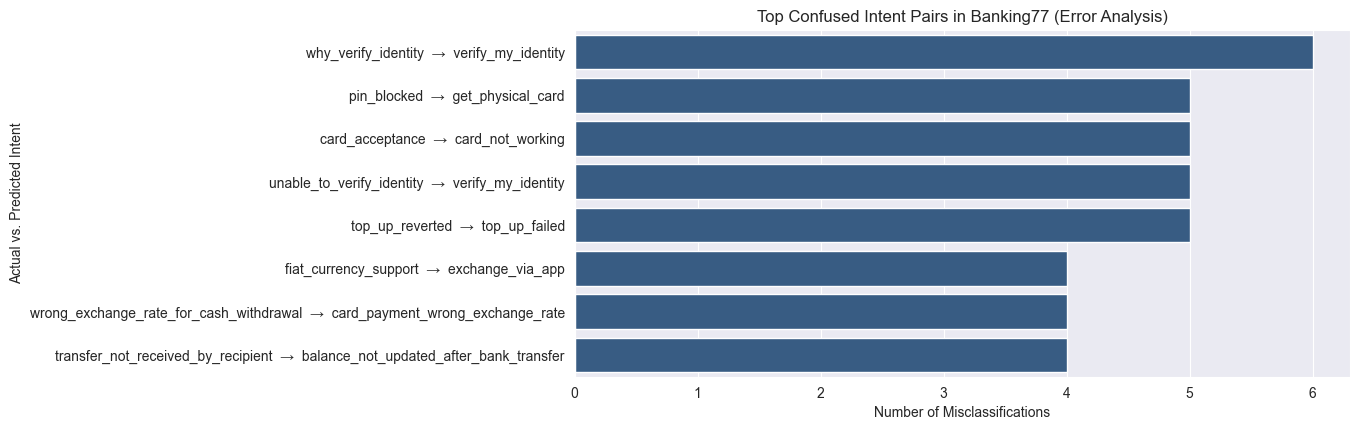

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4.5))
pair_labels = confused_pairs['Actual Intent'] + "  →  " + confused_pairs['Predicted Intent']
sns.barplot(x=confused_pairs['Error Count'], y=pair_labels, color='#2b5c8f')

plt.title("Top Confused Intent Pairs in Banking77 (Error Analysis)", fontsize=12)
plt.xlabel("Number of Misclassifications")
plt.ylabel("Actual vs. Predicted Intent")

plt.savefig("top_confused_intents.png", dpi=200, bbox_inches='tight')
plt.show()